<a href="https://colab.research.google.com/github/nattaponm/Teach_Tdating_strom_tracks_HID_CloudProperties/blob/main/notebooks/05_terrain_and_storm_physics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 5: ภูมิประเทศ (DEM) กับกายภาพเมฆตามเส้นทางพายุ
### Terrain and storm properties: initiation height, terrain classes, orographic lifting — and the range/beam-height confounder

⏱️ เวลาเรียนโดยประมาณ **90 นาที** | ต้องผ่าน: Notebook 3–4

---
## 🎯 วัตถุประสงค์การเรียนรู้
เมื่อจบ notebook นี้ นิสิตจะสามารถ
1. **ดึงค่าภูมิประเทศใต้เซลล์** (ความสูง ความชัน relief) และคำนวณ **แรงยกจากภูมิประเทศ** $w_{oro} = \mathbf{v}\cdot\nabla h$
2. **ทดสอบว่าพายุก่อตัวบนพื้นที่สูงกว่าปกติหรือไม่** ด้วย permutation test
3. **เปรียบเทียบกายภาพเมฆ (Z, HID, KDP, Doppler) ตามชั้นความสูงภูมิประเทศ** และตามการเคลื่อนขึ้น/ลงลาด
4. **ระบุและควบคุมตัวแปรแทรกซ้อน** — ระยะจากเรดาร์และความสูงลำคลื่น — ด้วยการแบ่งชั้น (stratification) และ partial correlation
5. **สังเคราะห์ข้อค้นพบของ repo ทั้งหมด** และวางแผนงานวิจัยต่อยอด

## 📖 1. แนวคิดและสมการ

### 1.1 ภูมิประเทศกับพายุฤดูร้อน (Houze, 2012; Kirshbaum et al., 2018)
- **การยกตัวเชิงกล (mechanical lifting):** ลมพัดขึ้นลาดเขา → อากาศถูกยกถึงระดับควบแน่น/LFC
- **การยกตัวเชิงความร้อน (thermal forcing):** ที่สูงร้อนเร็วตอนกลางวัน → เกิดลมหุบเขา–ภูเขา และการลอยตัวแรงเหนือยอดเขา
- อีสานด้านตะวันตกมีแนวเขา **เพชรบูรณ์–เลย (ภูกระดึง ~1,300 m)** ติดกับที่ราบสูงโคราช (~150–250 m) — ใน repo pysteps พบว่าพายุเริ่มก่อตัวราว 12:00 น. บนพื้นที่สูง ~888 m

### 1.2 สมการ
ความชันและ relief:
$$ |\nabla h| = \sqrt{(\partial h/\partial x)^2 + (\partial h/\partial y)^2},\qquad \text{slope} = \arctan|\nabla h|,\qquad \text{relief}_{5km} = h_{max} - h_{min} $$
แรงยกจากภูมิประเทศ (ความเร็วแนวดิ่งที่เกิดจากการเคลื่อนข้ามความลาด):
$$ w_{oro} = u\frac{\partial h}{\partial x} + v\frac{\partial h}{\partial y}\quad[\mathrm{m\,s^{-1}}],\qquad w_{oro} > 0\ \Rightarrow\ \text{ขึ้นลาด (upslope)} $$
⚠️ ใช้ความเร็วของ **พายุ** (centroid) แทนลมระดับต่ำ — เป็นตัวแทนอย่างหยาบ งานวิจัยจริงควรใช้ลมจาก reanalysis/แบบจำลอง

### 1.3 ตัวแปรแทรกซ้อน (confounder): ระยะจากเรดาร์
ภูเขาทางตะวันตกอยู่ห่างเรดาร์ KKN 90–200 km → ลำคลื่นมุม 0.48° อยู่สูง 1.5–4 km
ถ้าเห็นว่า "พายุบนภูเขาอ่อนกว่า" อาจเพราะเรดาร์ **มองสูงเกินแกนพายุ** ไม่ใช่เพราะภูเขา
$$ \rho_{xy\cdot z} = \mathrm{corr}\big(e_x, e_y\big),\quad e_x = R(x) - \hat{R}(x\,|\,R(z)),\ \ e_y = R(y) - \hat{R}(y\,|\,R(z)) $$
($R$ = อันดับ, $z$ = ความสูงลำคลื่น) — partial Spearman ตัดผลของ $z$ ออกจากทั้ง $x$ และ $y$

## ⚙️ 2. เตรียมสภาพแวดล้อมและข้อมูล

In [1]:
#@title ⚙️ Setup: ติดตั้งแพ็กเกจและดาวน์โหลดข้อมูล (รันก่อนเสมอ ~2–4 นาทีใน Colab)
import os, sys, warnings
warnings.filterwarnings("ignore")

REPO = "Teach_Tdating_strom_tracks_HID_CloudProperties"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q pysteps==1.21.5 arm_pyart cartopy netCDF4 geopandas metpy cmweather rasterio scikit-image
    if not os.path.exists(REPO):
        !git clone -q --depth 1 https://github.com/nattaponm/{REPO}.git

for ROOT in [REPO, ".", ".."]:
    if os.path.exists(os.path.join(ROOT, "utils", "track_tools.py")):
        break
ROOT = os.path.abspath(ROOT)
sys.path.insert(0, ROOT)
DATA = os.path.join(ROOT, "data")
DER = os.path.join(DATA, "derived")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import track_tools as tt
from utils import mapplot as mp
from utils import kkn_tools as kt
mp.set_style()
mp.set_data_dir(DATA)
print("✅ พร้อมใช้งาน | ข้อมูลอยู่ที่:", DATA)

✅ พร้อมใช้งาน | ข้อมูลอยู่ที่: /content/Teach_Tdating_strom_tracks_HID_CloudProperties/data


In [2]:
terr = tt.load_terrain(os.path.join(DER, "KKN_20240503_terrain_1km.nc"))
polar, ptimes = tt.load_polar_grid(os.path.join(DER, "KKN_20240503_polar_15min.nc"))
SETS = {}
for dt in (15, 10, 5):
    S = tt.load_set(DER, tt.MAIN[dt])
    C = tt.cell_table(S["labels"], S["Z"], S["times"], S["meta"], terrain=terr, polar=polar, polar_times=ptimes,
                      beam=terr["beam_h0_km"])
    C = tt.add_motion(C, terr, S["meta"])
    T = tt.track_table(C)
    keep = T.index[T.lifetime_min >= 30]
    SETS[dt] = {**S, "C": C[C.track_id.isin(keep)].copy(), "T": tt.classify_tracks(T.loc[keep])}
meta = SETS[15]["meta"]
reports = kt.load_reports(DATA, meta)
cov = meta["coverage"]
print({dt: len(S["T"]) for dt, S in SETS.items()}, "เส้นทาง (อายุ ≥ 30 นาที)")

{15: 59, 10: 62, 5: 68} เส้นทาง (อายุ ≥ 30 นาที)


## 🏔️ 3. ภูมิประเทศและจุดก่อตัวของพายุ

บันทึกรูปแล้ว: figures/nb5_terrain_initiation_map.png, figures/nb5_terrain_initiation_map.pdf


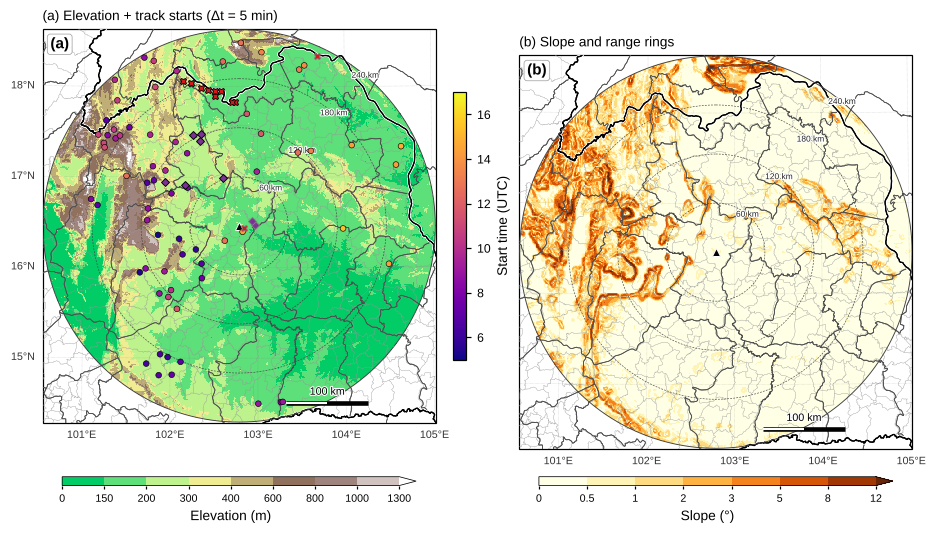

In [3]:
import matplotlib as mpl
fig, axs = mp.map_panels(1, 2, meta, panel_width=4.2)
lv = [0, 150, 200, 300, 400, 600, 800, 1000, 1300]
cm_ter = mpl.colors.ListedColormap(mpl.colormaps["terrain"](np.linspace(0.25, 1.0, 256)))   # ตัดส่วนสีน้ำเงิน (ไม่ใช่น้ำ)
im0 = mp.field_map(axs[0], np.where(cov, terr["elevation"], np.nan), meta, cmap=cm_ter, levels=lv, label="Elevation (m)",
                   title="(a) Elevation + track starts (Δt = 5 min)", extend="max")
T5 = SETS[5]["T"]
sc = axs[0].scatter(*kt.lonlat_to_xy(meta, T5.start_lon.values, T5.start_lat.values), c=T5.start.dt.hour + T5.start.dt.minute / 60,
                    cmap="plasma", vmin=5, vmax=17, s=14, edgecolor="k", lw=0.4, transform=mp.get_crs(meta), zorder=9)
mp.add_reports(axs[0], reports, legend=False, ms=4)
im1 = mp.field_map(axs[1], np.where(cov, terr["slope"], np.nan), meta, cmap="YlOrBr", levels=[0, 0.5, 1, 2, 3, 5, 8, 12],
                   label="Slope (°)", title="(b) Slope and range rings", gridline_labels=("bottom",), extend="max")
mp.add_colorbar(fig, im0, axs[0], shrink=0.9, extend="max")
mp.add_colorbar(fig, im1, axs[1], shrink=0.9, extend="max")
cb = fig.colorbar(sc, ax=axs[0], orientation="vertical", shrink=0.6, pad=0.01); cb.set_label("Start time (UTC)")
mp.panel_labels(axs)
mp.save_figure(fig, "nb5_terrain_initiation_map")
plt.show()

บันทึกรูปแล้ว: figures/nb5_initiation_ecdf.png, figures/nb5_initiation_ecdf.pdf


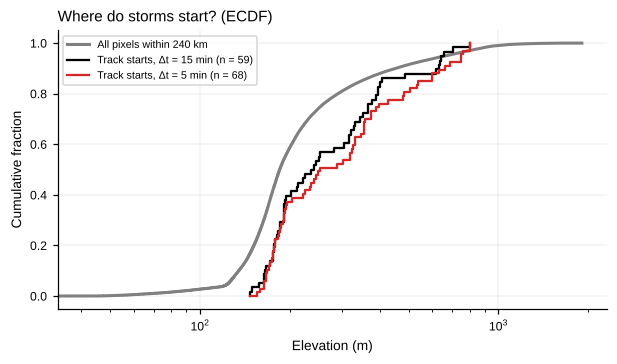

ความสูงมัธยฐาน: ทั้งพื้นที่ 185 m | จุดเริ่มเส้นทาง Δt 15 นาที 236 m, Δt 5 นาที 251 m


In [4]:
bg = terr["elevation"][cov]
fig, ax = plt.subplots(figsize=(5.5, 3.2), layout="constrained")
x = np.sort(bg); ax.plot(x, np.linspace(0, 1, len(x)), color="0.5", lw=2, label="All pixels within 240 km")
for dt, col in ((15, "k"), (5, "tab:red")):
    v = np.sort(SETS[dt]["T"]["dem_start"].dropna())
    ax.step(v, np.linspace(0, 1, len(v)), where="post", color=col, label=f"Track starts, Δt = {dt} min (n = {len(v)})")
ax.set_xscale("log"); ax.set_xlabel("Elevation (m)"); ax.set_ylabel("Cumulative fraction"); ax.legend(fontsize=7)
ax.grid(lw=0.3, alpha=0.5); ax.set_title("Where do storms start? (ECDF)", loc="left")
mp.save_figure(fig, "nb5_initiation_ecdf")
plt.show()
print(f"ความสูงมัธยฐาน: ทั้งพื้นที่ {np.median(bg):.0f} m | จุดเริ่มเส้นทาง Δt 15 นาที {SETS[15]['T'].dem_start.median():.0f} m, "
      f"Δt 5 นาที {SETS[5]['T'].dem_start.median():.0f} m")

ถ้าเส้นโค้งของจุดเริ่มเส้นทาง **อยู่ทางขวา** ของเส้นสีเทา = พายุมักเริ่มบนพื้นที่สูงกว่าพื้นที่ทั่วไป (ทดสอบนัยสำคัญในแบบฝึกหัด 5.1)
ข้อควรระวัง: "จุดเริ่มเส้นทาง" คือที่ที่ T-DaTing **เห็นเซลล์ครั้งแรก** (≥ 33 dBZ, ≥ 15 km²) ไม่ใช่จุดที่เมฆเริ่มก่อตัวจริง

## 📊 4. กายภาพเมฆตามชั้นความสูงภูมิประเทศ (Δt = 15 นาที)

บันทึกรูปแล้ว: figures/nb5_boxplots_terrain.png, figures/nb5_boxplots_terrain.pdf


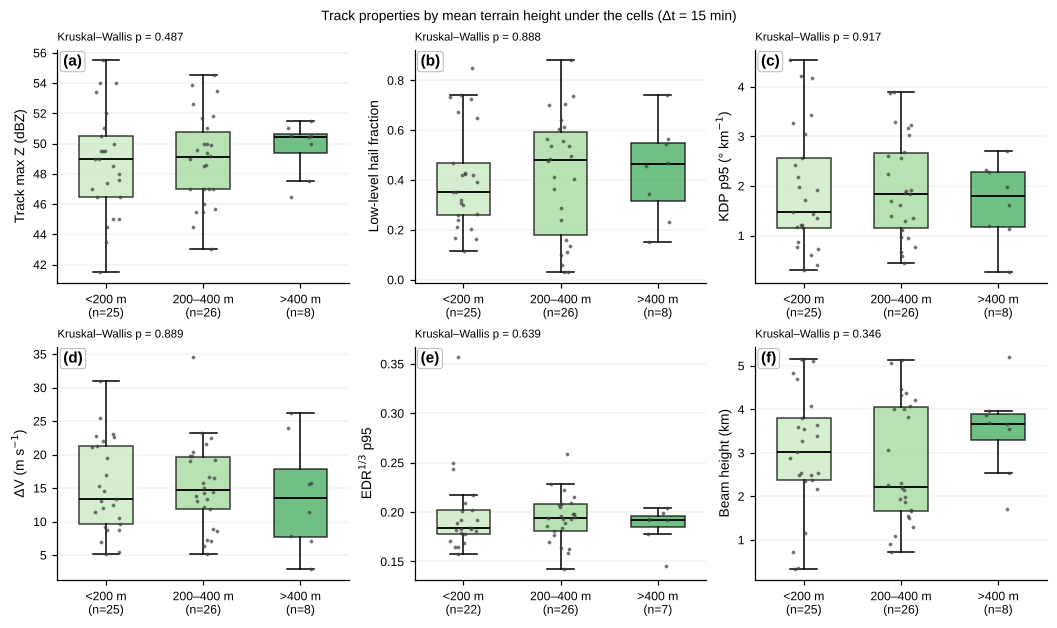

In [5]:
T15 = SETS[15]["T"]
vars_ = [("Zmax_obs", "Track max Z (dBZ)"), ("hail_low_frac", "Low-level hail fraction"),
         ("KDP95", "KDP p95 (° km$^{-1}$)"), ("dV", "ΔV (m s$^{-1}$)"), ("EDR95", "EDR$^{1/3}$ p95"), ("beam_h_km", "Beam height (km)")]
fig, axs = plt.subplots(2, 3, figsize=(9.5, 5.6), layout="constrained")
for ax, (v, lab) in zip(axs.ravel(), vars_):
    tt.boxplot_groups(ax, T15, v, "terrain_class", colors=["#c7e9c0", "#a1d99b", "#41ab5d"], ylabel=lab)
    H, p, _ = tt.kruskal_dunn(T15, v, "terrain_class")
    ax.set_title(f"Kruskal–Wallis p = {p:.3f}", loc="left", fontsize=7.5)
mp.panel_labels(axs.ravel())
fig.suptitle("Track properties by mean terrain height under the cells (Δt = 15 min)", fontsize=9)
mp.save_figure(fig, "nb5_boxplots_terrain")
plt.show()

**สังเกตแผง (f):** ถ้าความสูงลำคลื่นต่างกันมากระหว่างชั้นภูมิประเทศ การเปรียบเทียบในแผง (a)–(e) ถูก "ปน" ด้วยระยะจากเรดาร์ — ต้องจัดการก่อนสรุป

## ⚠️ 5. ตัวแปรแทรกซ้อน: ภูมิประเทศ × ระยะจากเรดาร์

จำนวนเส้นทาง: ชั้นภูมิประเทศ × ช่วงระยะ (Δt = 15 นาที)
range_class    <100 km  100–160 km  >160 km  All
terrain_class                                   
<200 m               4           9       12   25
200–400 m            6          10       10   26
>400 m               0           2        6    8
All                 10          21       28   59


บันทึกรูปแล้ว: figures/nb5_confounding_range.png, figures/nb5_confounding_range.pdf


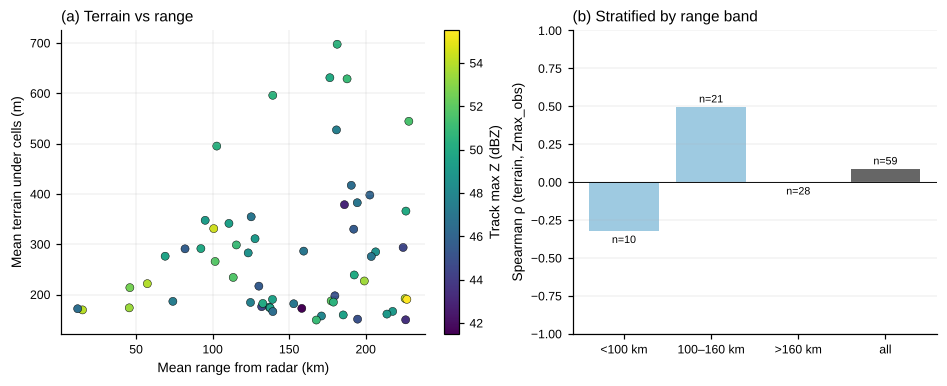

ρ(terrain, Zmax_obs) รวม = 0.09 | partial ρ ควบคุมความสูงลำคลื่น = 0.10 (p = 0.445, n = 59)


In [6]:
print("จำนวนเส้นทาง: ชั้นภูมิประเทศ × ช่วงระยะ (Δt = 15 นาที)")
print(pd.crosstab(T15.terrain_class, T15.range_class, margins=True))
from scipy.stats import spearmanr
fig, axs = plt.subplots(1, 2, figsize=(8.5, 3.4), layout="constrained")
sc = axs[0].scatter(T15.range_km, T15.dem_mean, c=T15.Zmax_obs, cmap="viridis", s=28, edgecolor="k", lw=0.3)
fig.colorbar(sc, ax=axs[0], label="Track max Z (dBZ)")
axs[0].set_xlabel("Mean range from radar (km)"); axs[0].set_ylabel("Mean terrain under cells (m)"); axs[0].grid(lw=0.3, alpha=0.5)
axs[0].set_title("(a) Terrain vs range", loc="left")
rows = []
for lab_, g in T15.groupby("range_class", observed=True):
    if len(g) >= 6:
        rows.append({"range": str(lab_), "n": len(g), "rho": spearmanr(g.dem_mean, g.Zmax_obs, nan_policy="omit")[0]})
rows.append({"range": "all", "n": len(T15), "rho": spearmanr(T15.dem_mean, T15.Zmax_obs, nan_policy="omit")[0]})
strat = pd.DataFrame(rows)
axs[1].bar(strat["range"], strat["rho"], color=["#9ecae1"] * (len(strat) - 1) + ["0.4"])
for k_, r_ in strat.iterrows():
    axs[1].text(k_, r_.rho + (0.03 if r_.rho >= 0 else -0.08), f"n={r_.n}", ha="center", fontsize=7)
axs[1].axhline(0, color="k", lw=0.6); axs[1].set_ylabel("Spearman ρ (terrain, Zmax_obs)"); axs[1].set_ylim(-1, 1)
axs[1].set_title("(b) Stratified by range band", loc="left"); axs[1].grid(axis="y", lw=0.3, alpha=0.5)
mp.save_figure(fig, "nb5_confounding_range")
plt.show()
r_p, p_p, n_p = tt.partial_spearman(T15, "dem_mean", "Zmax_obs", "beam_h_km")
print(f"ρ(terrain, Zmax_obs) รวม = {strat.iloc[-1].rho:.2f} | partial ρ ควบคุมความสูงลำคลื่น = {r_p:.2f} (p = {p_p:.3f}, n = {n_p})")

- (b) ความสัมพันธ์ภูมิประเทศ–ความแรง **ต่างกันในแต่ละช่วงระยะ** — ภาพรวม (แท่งเทา) อาจซ่อนสัญญาณที่มีอยู่ในบางช่วงระยะ (Simpson's paradox แบบอ่อน)
- จำนวนเส้นทางในแต่ละช่องของตาราง crosstab **น้อย** → ผลไม่มั่นคง ต้องรวมหลายพายุ/หลายวันก่อนสรุป

## ⛰️ 6. แรงยกจากภูมิประเทศ: เซลล์ที่เคลื่อน "ขึ้นลาด" แรงกว่าหรือไม่?

บันทึกรูปแล้ว: figures/nb5_boxplots_upslope.png, figures/nb5_boxplots_upslope.pdf


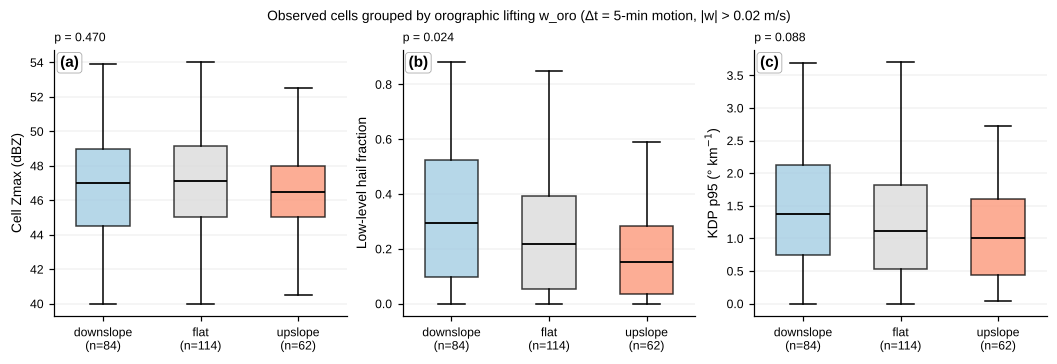

{'flat': 114, 'downslope': 84, 'upslope': 62}


In [7]:
C5 = SETS[5]["C"]
obs5 = C5[C5.observed & C5.w_oro_ms.notna()].copy()
thr = 0.02                                                     # m/s
obs5["slope_motion"] = pd.cut(obs5.w_oro_ms, [-10, -thr, thr, 10], labels=["downslope", "flat", "upslope"])
fig, axs = plt.subplots(1, 3, figsize=(9.5, 3.2), layout="constrained")
for ax, (v, lab) in zip(axs, (("Zmax", "Cell Zmax (dBZ)"), ("hail_low_frac", "Low-level hail fraction"), ("KDP95", "KDP p95 (° km$^{-1}$)"))):
    tt.boxplot_groups(ax, obs5, v, "slope_motion", colors=["#9ecae1", "#d9d9d9", "#fc9272"], ylabel=lab, points=False)
    H, p, _ = tt.kruskal_dunn(obs5, v, "slope_motion")
    ax.set_title(f"p = {p:.3f}", loc="left", fontsize=8)
mp.panel_labels(axs)
fig.suptitle(f"Observed cells grouped by orographic lifting w_oro (Δt = 5-min motion, |w| > {thr} m/s)", fontsize=9)
mp.save_figure(fig, "nb5_boxplots_upslope")
plt.show()
print(obs5.slope_motion.value_counts().to_dict())

- $w_{oro}$ ส่วนใหญ่มีขนาดเล็ก (ที่ราบสูงโคราชค่อนข้างราบ) — กลุ่ม upslope/downslope เกิดเฉพาะบริเวณขอบที่สูงทางตะวันตกและเหนือ
- หน่วยในกราฟนี้คือ **เซลล์** (หลายเซลล์จากเส้นทางเดียวกัน) จึงไม่เป็นอิสระต่อกัน p-value ต่ำเกินจริง → ใช้เป็นการสำรวจ ไม่ใช่การยืนยัน

## 🧾 7. สังเคราะห์ข้อค้นพบของ repo

In [8]:
T5_, T15_ = SETS[5]["T"], SETS[15]["T"]
synth = pd.DataFrame([
    ("NB1", "จำนวนเส้นทางอายุ ≥ 30 นาที (15 / 10 / 5 min)", " / ".join(str(len(SETS[d]["T"])) for d in (15, 10, 5))),
    ("NB1", "อายุสูงสุด (min) 15 / 5", f"{T15_.lifetime_min.max():.0f} / {T5_.lifetime_min.max():.0f}"),
    ("NB3", "ความเร็วพายุมัธยฐาน (km/h) 15 / 5", f"{T15_.speed_kmh.median():.0f} / {T5_.speed_kmh.median():.0f}"),
    ("NB3", "Zmax_obs มัธยฐาน (dBZ)", f"{T15_.Zmax_obs.median():.1f}"),
    ("NB4", "ρ(D_eq, KDP95) 15 / 5", f"{spearmanr(T15_.deq_max, T15_.KDP95, nan_policy='omit')[0]:.2f} / "
                                    f"{spearmanr(T5_.deq_max, T5_.KDP95, nan_policy='omit')[0]:.2f}"),
    ("NB4", "ρ(lifetime, hail area) 15 / 5", f"{spearmanr(T15_.lifetime_min, T15_.hail_col_km2, nan_policy='omit')[0]:.2f} / "
                                           f"{spearmanr(T5_.lifetime_min, T5_.hail_col_km2, nan_policy='omit')[0]:.2f}"),
    ("NB5", "ความสูงจุดเริ่มเส้นทางมัธยฐาน vs พื้นที่ทั้งหมด (m)", f"{T15_.dem_start.median():.0f} vs {np.median(bg):.0f}"),
    ("NB5", "ρ(terrain, Zmax_obs) รวม / partial | beam height", f"{strat.iloc[-1].rho:.2f} / {r_p:.2f}"),
], columns=["notebook", "indicator", "value"])
synth

,notebook,indicator,value
0,NB1,จำนวนเส้นทางอายุ ≥ 30 นาที (15 / 10 / 5 min),59 / 62 / 68
1,NB1,อายุสูงสุด (min) 15 / 5,120 / 135
2,NB3,ความเร็วพายุมัธยฐาน (km/h) 15 / 5,17 / 24
3,NB3,Zmax_obs มัธยฐาน (dBZ),49.2
4,NB4,"ρ(D_eq, KDP95) 15 / 5",0.71 / 0.67
5,NB4,"ρ(lifetime, hail area) 15 / 5",0.31 / 0.46
6,NB5,ความสูงจุดเริ่มเส้นทางมัธยฐาน vs พื้นที่ทั้งหม...,236 vs 185
7,NB5,"ρ(terrain, Zmax_obs) รวม / partial | beam height",0.09 / 0.10


---
## 🧪 แบบฝึกหัด

### 🧪 แบบฝึกหัด 5.1: พายุเริ่มก่อตัวบนที่สูงกว่าปกติอย่างมีนัยสำคัญหรือไม่?
ใช้ `tt.permutation_test(sample, population)` ทดสอบว่ามัธยฐานของ `dem_start` (Δt = 15 และ 5 นาที) สูงกว่ามัธยฐานของความสูงที่สุ่มจาก pixel ทั้งหมดในรัศมีเรดาร์หรือไม่
ทำซ้ำโดยจำกัด population เฉพาะ **pixel ที่มี echo ≥ 33 dBZ อย่างน้อยหนึ่งครั้งในวัน** (พื้นที่ที่พายุ "มีโอกาส" เกิด)

**คำถาม:** ผลเปลี่ยนไปหรือไม่เมื่อเปลี่ยน population? การเลือก "กลุ่มเปรียบเทียบ" สำคัญอย่างไรในงานวิจัยเชิงพื้นที่

<details>
<summary><b>💡 คำใบ้</b></summary>

- population ที่ 2: `ever = np.nanmax(SETS[15]["Z"], axis=0) >= 33` แล้ว `terr["elevation"][ever & cov]`
- `obs, expected, p = tt.permutation_test(T.dem_start.dropna().values, population)`

</details>

In [9]:
# ✍️ แบบฝึกหัด 5.1 — เขียนโค้ดของคุณที่นี่

In [10]:
#@title ✅ เฉลยแบบฝึกหัด 5.1
ever = np.nanmax(np.nan_to_num(SETS[15]["Z"], nan=-15), axis=0) >= 33
pops = {"all pixels ≤ 240 km": terr["elevation"][cov], "pixels with ≥33 dBZ that day": terr["elevation"][ever & cov]}
rows = []
for dt in (15, 5):
    smp = SETS[dt]["T"]["dem_start"].dropna().values
    for name, pop in pops.items():
        o, e, p = tt.permutation_test(smp, pop, n=5000)
        rows.append({"dt_min": dt, "population": name, "n": len(smp), "median_starts_m": o, "median_random_m": e, "p_one_sided": p})
print(pd.DataFrame(rows).round(3))
print("\n→ เทียบกับ 'ทั้งพื้นที่' ตอบคำถามว่า 'พายุชอบที่สูงหรือไม่' ; เทียบกับ 'พื้นที่ที่มีพายุ' ตอบว่า 'ในบรรดาที่มีพายุ จุดเริ่มอยู่สูงกว่าจุดอื่นของเส้นทางหรือไม่'"
      "\n  กลุ่มเปรียบเทียบที่ต่างกันให้คำตอบต่อคำถามที่ต่างกัน — ต้องระบุให้ชัดในงานวิจัย")

   dt_min                    population   n  median_starts_m  median_random_m  \
0      15           all pixels ≤ 240 km  59          236.382          185.000   
1      15  pixels with ≥33 dBZ that day  59          236.382          202.000   
2       5           all pixels ≤ 240 km  68          250.885          185.000   
3       5  pixels with ≥33 dBZ that day  68          250.885          201.778   

   p_one_sided  
0        0.001  
1        0.028  
2        0.000  
3        0.003  

→ เทียบกับ 'ทั้งพื้นที่' ตอบคำถามว่า 'พายุชอบที่สูงหรือไม่' ; เทียบกับ 'พื้นที่ที่มีพายุ' ตอบว่า 'ในบรรดาที่มีพายุ จุดเริ่มอยู่สูงกว่าจุดอื่นของเส้นทางหรือไม่'
  กลุ่มเปรียบเทียบที่ต่างกันให้คำตอบต่อคำถามที่ต่างกัน — ต้องระบุให้ชัดในงานวิจัย


### 🧪 แบบฝึกหัด 5.2: ขึ้นลาดกับลงลาด — ระดับเส้นทาง
ปัญหาของ section 6 คือใช้เซลล์ที่ไม่เป็นอิสระต่อกัน ให้ทำใหม่ที่ **ระดับเส้นทาง** (Δt = 5 นาที):
จัดกลุ่มเส้นทางตาม `upslope_frac` (สัดส่วนเวลาที่ $w_{oro}$ > 0) เป็น "ส่วนใหญ่ขึ้นลาด" (> 0.5) กับ "ส่วนใหญ่ลงลาด/ราบ" (≤ 0.5)
แล้วเปรียบเทียบ `Zmax_obs`, `hail_low_frac`, `KDP95` ด้วย Mann–Whitney U และ Cliff's δ

**คำถาม:** ผลระดับเส้นทางเหมือนระดับเซลล์หรือไม่? ทำไมจึงต่างกันได้

<details>
<summary><b>💡 คำใบ้</b></summary>

- `T5["grp"] = np.where(T5.upslope_frac > 0.5, "mostly upslope", "mostly flat/down")`
- `from scipy.stats import mannwhitneyu`

</details>

In [11]:
# ✍️ แบบฝึกหัด 5.2 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb5_ex52_upslope_tracks.png, figures/nb5_ex52_upslope_tracks.pdf


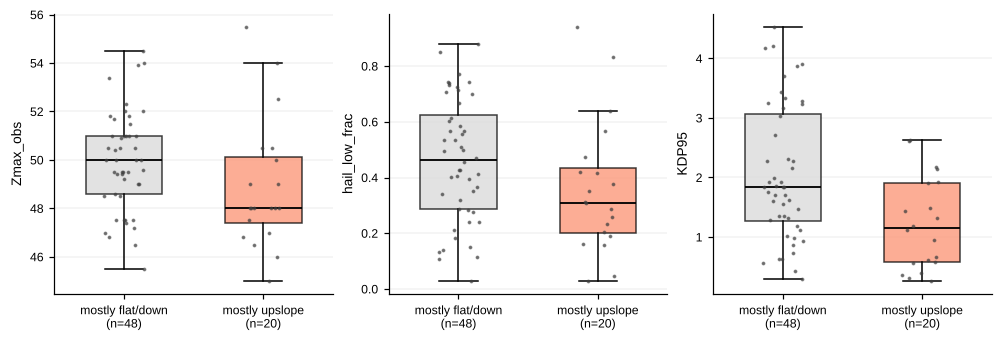

               n_up  n_flat_down  median_up  median_flat_down  cliffs_delta  \
variable                                                                      
Zmax_obs         20           48     48.000            50.000        -0.319   
hail_low_frac    20           48      0.310             0.463        -0.280   
KDP95            20           48      1.148             1.839        -0.425   

                   p  
variable              
Zmax_obs       0.040  
hail_low_frac  0.071  
KDP95          0.006  
→ เส้นทางที่ส่วนใหญ่ 'ขึ้นลาด' มี δ = {'Zmax_obs': -0.32, 'hail_low_frac': -0.28, 'KDP95': -0.42} (ค่าลบ = อ่อนกว่ากลุ่มราบ/ลงลาด)
  ระยะ/ความสูงลำคลื่น/ภูมิประเทศมัธยฐานของแต่ละกลุ่ม:
                   range_km  beam_h_km  dem_mean
grp                                            
mostly flat/down     138.9        2.5     231.6
mostly upslope       191.2        4.0     316.7
  ถ้ากลุ่มขึ้นลาดอยู่ไกลกว่าและลำคลื่นสูงกว่า ผลที่ 'อ่อนกว่า' อาจมาจากเรดาร์มองสูงเกินแกนพายุ ไม่ใช่จากภูเขา (

In [12]:
#@title ✅ เฉลยแบบฝึกหัด 5.2
from scipy.stats import mannwhitneyu
T5g = SETS[5]["T"].copy()
T5g["grp"] = pd.Categorical(np.where(T5g.upslope_frac > 0.5, "mostly upslope", "mostly flat/down"),
                            ["mostly flat/down", "mostly upslope"])
rows = []
fig, axs = plt.subplots(1, 3, figsize=(9, 3), layout="constrained")
for ax, v in zip(axs, ("Zmax_obs", "hail_low_frac", "KDP95")):
    a = T5g.loc[T5g.grp == "mostly upslope", v].dropna(); b = T5g.loc[T5g.grp == "mostly flat/down", v].dropna()
    p = mannwhitneyu(a, b)[1] if len(a) > 2 and len(b) > 2 else np.nan
    rows.append({"variable": v, "n_up": len(a), "n_flat_down": len(b), "median_up": a.median(), "median_flat_down": b.median(),
                 "cliffs_delta": tt.cliffs_delta(a, b), "p": p})
    tt.boxplot_groups(ax, T5g, v, "grp", colors=["#d9d9d9", "#fc9272"], ylabel=v)
mp.save_figure(fig, "nb5_ex52_upslope_tracks")
plt.show()
print(pd.DataFrame(rows).set_index("variable").round(3))
rr = pd.DataFrame(rows).set_index("variable")
print(f"→ เส้นทางที่ส่วนใหญ่ 'ขึ้นลาด' มี δ = {rr.cliffs_delta.round(2).to_dict()} (ค่าลบ = อ่อนกว่ากลุ่มราบ/ลงลาด)")
bh = T5g.groupby("grp", observed=True)[["range_km", "beam_h_km", "dem_mean"]].median().round(1)
print("  ระยะ/ความสูงลำคลื่น/ภูมิประเทศมัธยฐานของแต่ละกลุ่ม:\n", bh)
print("  ถ้ากลุ่มขึ้นลาดอยู่ไกลกว่าและลำคลื่นสูงกว่า ผลที่ 'อ่อนกว่า' อาจมาจากเรดาร์มองสูงเกินแกนพายุ ไม่ใช่จากภูเขา (ตัวแปรแทรกซ้อนเดิม)"
      "\n  และระดับเส้นทางมีตัวอย่างน้อยกว่าระดับเซลล์มาก — ระดับเซลล์ 'นับซ้ำ' พายุลูกเดียวกัน (pseudo-replication)")

### 🧪 แบบฝึกหัด 5.3: ภูมิประเทศสัมพันธ์กับตัวแปรใด หลังควบคุมความสูงลำคลื่น?
สำหรับ Δt = 15, 10, 5 นาที คำนวณ Spearman ρ และ partial ρ (ควบคุม `beam_h_km`) ระหว่าง `dem_mean` กับ
`Zmax_obs`, `hail_low_frac`, `graupel_up_frac`, `KDP95`, `dV`, `EDR95` แล้วทำ heatmap ของ partial ρ (แถว = ตัวแปร, คอลัมน์ = Δt)

**คำถาม:** มีความสัมพันธ์ใดที่ (1) คงทิศทางทุก Δt และ (2) ไม่หายไปเมื่อควบคุมความสูงลำคลื่นหรือไม่? ถ้าไม่มี แปลว่าอะไร

<details>
<summary><b>💡 คำใบ้</b></summary>

- `tt.partial_spearman(T, "dem_mean", v, "beam_h_km")[0]`
- `plt.imshow(M, cmap="RdBu_r", vmin=-1, vmax=1)`

</details>

In [13]:
# ✍️ แบบฝึกหัด 5.3 — เขียนโค้ดของคุณที่นี่

บันทึกรูปแล้ว: figures/nb5_ex53_partial_terrain.png, figures/nb5_ex53_partial_terrain.pdf


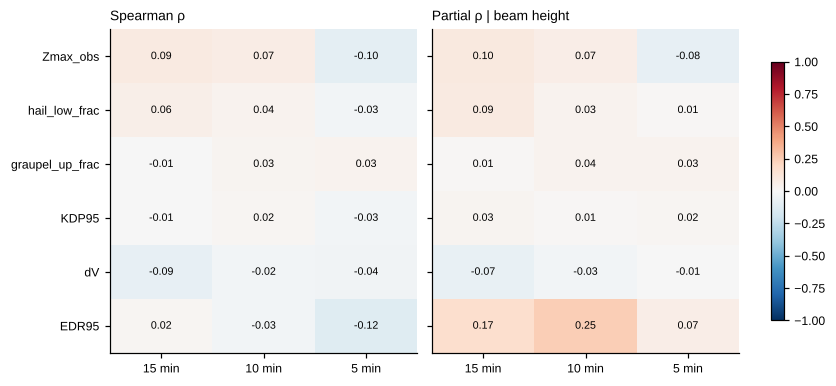

ตัวแปรที่ partial ρ ทิศเดียวกันทุก Δt และ |ρ| ≥ 0.2: ไม่มี
→ ถ้าไม่มีความสัมพันธ์ที่มั่นคง: จากพายุเพียงวันเดียว 'ยังสรุปไม่ได้' ว่าภูมิประเทศควบคุมความแรงของพายุ
  ไม่ได้แปลว่าไม่มีผล — ต้องเพิ่มจำนวนพายุ (หลายวัน/หลายปี) และใช้เรดาร์ที่อยู่ใกล้พื้นที่ภูเขามากกว่า (ลำคลื่นต่ำกว่า) ร่วมด้วย


In [14]:
#@title ✅ เฉลยแบบฝึกหัด 5.3
vlist = ["Zmax_obs", "hail_low_frac", "graupel_up_frac", "KDP95", "dV", "EDR95"]
R0 = pd.DataFrame({f"{dt} min": [spearmanr(SETS[dt]["T"].dem_mean, SETS[dt]["T"][v], nan_policy="omit")[0] for v in vlist]
                   for dt in (15, 10, 5)}, index=vlist)
R1 = pd.DataFrame({f"{dt} min": [tt.partial_spearman(SETS[dt]["T"], "dem_mean", v, "beam_h_km")[0] for v in vlist]
                   for dt in (15, 10, 5)}, index=vlist)
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.4), layout="constrained", sharey=True)
for ax, M, ttl in ((axs[0], R0, "Spearman ρ"), (axs[1], R1, "Partial ρ | beam height")):
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(3), M.columns); ax.set_yticks(range(len(vlist)), vlist); ax.set_title(ttl, loc="left", fontsize=9)
    for a in range(M.shape[0]):
        for b in range(M.shape[1]):
            ax.text(b, a, f"{M.iloc[a, b]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=list(axs), shrink=0.8)
mp.save_figure(fig, "nb5_ex53_partial_terrain")
plt.show()
consistent = [v for v in vlist if (np.sign(R1.loc[v]).nunique() == 1) and (R1.loc[v].abs().min() >= 0.2)]
print("ตัวแปรที่ partial ρ ทิศเดียวกันทุก Δt และ |ρ| ≥ 0.2:", consistent if consistent else "ไม่มี")
print("→ ถ้าไม่มีความสัมพันธ์ที่มั่นคง: จากพายุเพียงวันเดียว 'ยังสรุปไม่ได้' ว่าภูมิประเทศควบคุมความแรงของพายุ"
      "\n  ไม่ได้แปลว่าไม่มีผล — ต้องเพิ่มจำนวนพายุ (หลายวัน/หลายปี) และใช้เรดาร์ที่อยู่ใกล้พื้นที่ภูเขามากกว่า (ลำคลื่นต่ำกว่า) ร่วมด้วย")

---
## 📝 สรุป
- DEM ใต้เซลล์และ $w_{oro}$ คำนวณได้ง่ายจาก label ของ T-DaTing และกริดภูมิประเทศ 1 km
- จุดเริ่มเส้นทางเทียบกับพื้นที่ทั้งหมดบอกได้ว่าพายุ "ชอบ" ที่สูงหรือไม่ — แต่ผลขึ้นกับการเลือกกลุ่มเปรียบเทียบ
- ความสัมพันธ์ภูมิประเทศ–กายภาพเมฆ **ถูกปนด้วยระยะจากเรดาร์/ความสูงลำคลื่น** ต้องแบ่งชั้นหรือใช้ partial correlation และระวัง pseudo-replication
- ข้อมูลพายุหนึ่งวันเพียงพอสำหรับ **สร้างวิธีการและสมมติฐาน** แต่การยืนยันต้องใช้ข้อมูลหลายพายุ

### ❓ คำถามชวนคิด
1. ถ้าจะแยก "ผลของภูเขา" ออกจาก "ผลของเวลา" (พายุบ่ายเกิดบนเขา พายุค่ำเกิดที่ราบ) จะออกแบบการวิเคราะห์อย่างไร?
2. ทำไมการใช้ความเร็วพายุแทนลมระดับต่ำในการคำนวณ $w_{oro}$ อาจให้ผลผิด? ข้อมูลใดแทนได้ดีกว่า (ERA5, WRF, AWS)
3. เรดาร์ C-band มุมยกต่ำสุด 0.48° ถูกภูเขาบัง (beam blockage) ได้หรือไม่ในบริเวณเพชรบูรณ์–เลย? จะตรวจสอบจาก DEM อย่างไร

**🚀 ต่อยอดงานวิจัย (ป.โท / วิทยานิพนธ์)**
1. **ภูมิอากาศวิทยาเส้นทางพายุฤดูร้อนอีสาน** (มี.ค.–พ.ค. หลายปี) ด้วย workflow 00–05 → แผนที่ความถี่การก่อตัว ทิศทาง และความเสี่ยงลูกเห็บ
2. **บทบาทของภูมิประเทศ**: ใช้ข้อมูลหลายปีแบ่งชั้นตามระยะ/ความสูงลำคลื่น + ERA5 (CAPE, shear, ลมระดับต่ำ) ในแบบจำลองถดถอย (GLM/GAM)
3. **Beam blockage และ QPE บนพื้นที่ภูเขา**: คำนวณ partial beam blockage จาก DEM (เช่น wradlib) และผลต่อสถิติเส้นทาง
4. **Machine learning ทำนายเส้นทางที่ก่อความเสียหาย**: features จาก NB3–NB5, label จากรายงาน ปภ., ประเมินด้วย spatial cross-validation

### 📚 เอกสารอ้างอิง
- Houze, R. A. (2012). Orographic effects on precipitating clouds. *Rev. Geophys.*, 50, RG1001.
- Kirshbaum, D. J., Adler, B., Kalthoff, N., Barthlott, C., & Serafin, S. (2018). Moist orographic convection: Physical mechanisms and links to surface-exchange processes. *Atmosphere*, 9, 80.
- Wilks, D. S. (2019). *Statistical Methods in the Atmospheric Sciences* (4th ed.). Elsevier.
- Hurlbert, S. H. (1984). Pseudoreplication and the design of ecological field experiments. *Ecological Monographs*, 54, 187–211.
- Bech, J., Codina, B., Lorente, J., & Bebbington, D. (2003). The sensitivity of single polarization weather radar beam blockage correction to variability in the vertical refractivity gradient. *J. Atmos. Oceanic Technol.*, 20, 845–855.